# 04 - LSTM autoencoder for collective anomalies (Day 10)

**Question:** can a model that has only ever seen *normal* sensor behaviour tell that a window of
60 consecutive readings is abnormal - in particular the slow equipment-degradation drift
("collective" anomaly) that single-value detectors (Z-score, IQR) are blind to - and how far can
the signal be trusted (threshold, per-feature localisation, MC-Dropout uncertainty)?

The model (`src/models/lstm_autoencoder.py`) is an LSTM encoder (64 -> 128) -> variational
bottleneck -> LSTM decoder (128 -> 64) with LayerNorm after every LSTM layer and dropout 0.2
between layers. It is trained on **normal windows only**; a window is flagged when its
reconstruction error exceeds `mean + 3 * std` of the errors on normal validation windows.

Same data and test period as Days 8 and 9 (simulated warehouse sensors, seed 7), strictly
chronological, nothing tuned on the test period:

| Segment | Period (UTC) | Used for |
|---|---|---|
| cold start | 21:45 - 22:00 | discarded (aggregator windows not yet filled) |
| **train** | 22:00 - 00:30 | fits the scaler and the weights (**normal windows only**) |
| **validation** | 00:30 - 01:30 | early stopping, LR schedule and the alarm threshold (**normal windows only**) |
| **test** | 01:30 - 05:30 | all reported numbers, all window types |

Labels are used to *select* clean windows for training and to *evaluate* - never as a model input.

In [1]:
import sys, os, time, json, logging, warnings
from pathlib import Path
from datetime import datetime, UTC, timedelta

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
logging.getLogger("src").setLevel(logging.WARNING)      # silence per-run INFO logs
warnings.filterwarnings("ignore")

from IPython.display import Markdown, display
from src.models.offline_dataset import simulate_labeled_features
from src.models.feature_engineering import OnlineScaler
from src.models.lstm_autoencoder import (
    LSTMAutoencoder, LSTMAutoencoderTrainer, LSTMAutoencoderDetector, make_sequences,
    reconstruction_errors, select_features, train_detector, TEMPORAL_FEATURES)
from src.models.model_registry import ModelRegistry
from src.utils.config import get_config

sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})
PAL = sns.color_palette("colorblind")
TYPES = ["point", "contextual", "collective"]
T = lambda day, h, m=0: datetime(2026, 11, day, h, m, tzinfo=UTC)
SEED = 7
cfg = get_config().models.lstm_autoencoder
SEQ = cfg.seq_len
print(f"torch {torch.__version__}, threads {torch.get_num_threads()};  config: seq_len={SEQ}, "
      f"hidden={cfg.hidden_sizes}, latent={cfg.latent_dim}, dropout={cfg.dropout}, kl_weight={cfg.kl_weight}, "
      f"patience={cfg.early_stopping_patience}, MC passes={cfg.mc_dropout_passes}, sigma={cfg.threshold_sigma}")

torch 2.15.0+cu132, threads 2;  config: seq_len=60, hidden=(64, 128), latent=32, dropout=0.2, kl_weight=0.1, patience=10, MC passes=10, sigma=3.0


## 1. Data: the production feature path, run offline

In [2]:
t0 = time.time()
ds = simulate_labeled_features(7.75 * 3600, start_time=T(20, 21, 45), seed=SEED)["warehouse"]
print(f"{len(ds):,} warehouse events -> feature vectors in {time.time()-t0:.0f}s, "
      f"{len(ds.feature_names)} features, {len(set(ds.entity_ids))} sensors")

SEG = {"train": (T(20, 22), T(21, 0, 30)),
       "validation": (T(21, 0, 30), T(21, 1, 30)),
       "test": (T(21, 1, 30), T(21, 5, 30))}
# a window ends at its newest row, so its first row is SEQ seconds earlier: start windows SEQ s into
# the segment so no window straddles a segment boundary
seg_w = lambda k: (SEG[k][0] + timedelta(seconds=SEQ), SEG[k][1])

rows = []
for k in SEG:
    part = ds.subset(ds.between(*SEG[k]) & ds.warm)
    c = part.type_counts()
    rows.append(dict(segment=k, rows=len(part), anomaly_rate=round(part.anomaly_rate, 4), **{t: c.get(t, 0) for t in TYPES}))
pd.DataFrame(rows).set_index("segment")

334,800 warehouse events -> feature vectors in 25s, 30 features, 12 sensors


,rows,anomaly_rate,point,contextual,collective
segment,,,,,
train,108000,0.0326,2072,864,585
validation,43200,0.0681,801,1989,152
test,172800,0.0634,3351,6786,824


**Scaler.** Features are standardised with the pipeline's `OnlineScaler`, fitted on the *normal
training rows only* (so anomalies cannot stretch the scale). Serving must use this same scaler -
it is saved with the model in section 11.

In [3]:
fit_rows = ds.subset(ds.between(*SEG["train"]) & ds.warm & ~ds.y)
scaler = OnlineScaler(len(ds.feature_names), clip=10.0)
scaler.fit_update(fit_rows.X)
print(f"scaler fitted on {len(fit_rows):,} normal training rows")

W_all = make_sequences(ds, scaler, seq_len=SEQ, stride=10)       # all features, for the diagnostic below
print(f"{len(W_all):,} windows of shape {W_all.x.shape[1:]}  ({W_all.normal.mean():.0%} contain no anomalous row at all)")

scaler fitted on 104,479 normal training rows


32,448 windows of shape (60, 30)  (48% contain no anomalous row at all)


## 2. Which features should the autoencoder see?

The pipeline's feature vector also holds cyclical *clock* encodings (`hour_*`, `dow_*`, `minute_*`).
They are pure functions of the timestamp, so they cannot say anything about a drifting sensor, but
a model trained on a couple of hours cannot reconstruct an hour or weekday it has not seen. To check
whether that matters, train a model on **all** features for a few epochs and compare, per feature,
its validation error with the error of the trivial "predict the training mean" model
(`error / mean-square = 1`).

6,473 train / 1,690 validation windows, 12 epochs in 232s


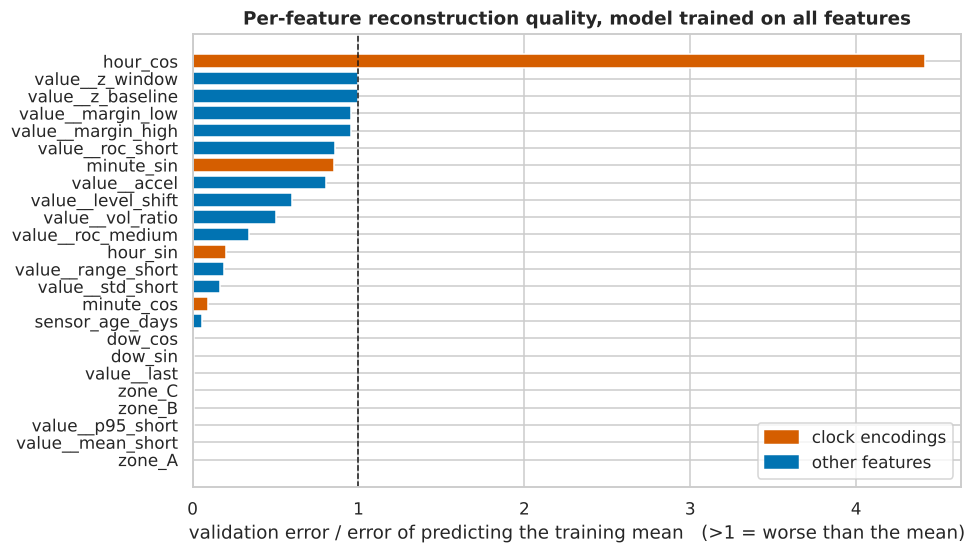

clock encodings: 6 of 24 non-constant features, 34% of the total reconstruction error
           feature  model_mse  ratio
          hour_cos      0.928  4.414
   value__z_window      0.973  0.999
 value__z_baseline      0.933  0.999
 value__margin_low      0.911  0.954
value__margin_high      0.911  0.954
  value__roc_short      0.571  0.857
        minute_sin      0.908  0.853
      value__accel      0.569  0.806


In [4]:
d_tr = W_all.subset(W_all.between(*seg_w("train")) & W_all.normal)
d_va = W_all.subset(W_all.between(*seg_w("validation")) & W_all.normal)
torch.manual_seed(0)
m_all = LSTMAutoencoder.from_config(cfg, len(ds.feature_names))
t0 = time.time()
h_all = LSTMAutoencoderTrainer.from_config(cfg, m_all, max_epochs=12, patience=12, log_dir=None).fit(d_tr.x, d_va.x)
print(f"{len(d_tr):,} train / {len(d_va):,} validation windows, {h_all.epochs_run} epochs in {time.time()-t0:.0f}s")

pf = reconstruction_errors(m_all, d_va.x).per_feature.mean(axis=0)
ms = (d_va.x ** 2).mean(axis=(0, 1))                       # error of predicting the training mean
diag = pd.DataFrame({"feature": W_all.feature_names, "model_mse": pf, "mean_square": ms})
diag = diag[diag.mean_square > 1e-6].assign(ratio=lambda d: d.model_mse / d.mean_square,
                                             clock=lambda d: d.feature.isin(TEMPORAL_FEATURES))
diag = diag.sort_values("ratio", ascending=False)

fig, ax = plt.subplots(figsize=(9, 5.2))
ax.barh(diag.feature[::-1], diag.ratio[::-1], color=[PAL[3] if c else PAL[0] for c in diag.clock[::-1]])
ax.axvline(1, color="k", ls="--", lw=1); ax.set_xlabel("validation error / error of predicting the training mean   (>1 = worse than the mean)")
ax.set_title("Per-feature reconstruction quality, model trained on all features")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=PAL[3]), plt.Rectangle((0, 0), 1, 1, color=PAL[0])],
          labels=["clock encodings", "other features"], loc="lower right")
plt.tight_layout(); plt.show()

clock_share = diag[diag.clock].model_mse.sum() / diag.model_mse.sum()
print(f"clock encodings: {diag.clock.sum()} of {len(diag)} non-constant features, "
      f"{clock_share:.0%} of the total reconstruction error")
print(diag.head(8)[["feature", "model_mse", "ratio"]].round(3).to_string(index=False))

In [5]:
worse = diag[diag.clock & (diag.ratio > 1)]
worse_txt = "; " + ", ".join(f"`{f}` is reconstructed {r:.1f}x worse than a constant" for f, r in zip(worse.feature, worse.ratio)) if len(worse) else ""
display(Markdown(f'''
The clock encodings are {int(diag.clock.sum())} of {len(diag)} non-constant features but {clock_share:.0%} of the total reconstruction error{worse_txt}.
They are pure functions of the timestamp, so they cannot say anything about a drifting sensor, and a model trained on a few hours cannot
learn hours it has not seen. The model therefore gets `select_features(...)`: all features except the clock encodings. (Zone one-hots and
sensor age stay: they are constant per sensor and cheap to reconstruct.) The detector receives the same column indices, so at serving time it
reads exactly these columns from the pipeline's sequence.

*Not tested here:* how much this choice changes the final detection metrics - that would need a second full training run.
'''))


The clock encodings are 6 of 24 non-constant features but 34% of the total reconstruction error; `hour_cos` is reconstructed 4.4x worse than a constant.
They are pure functions of the timestamp, so they cannot say anything about a drifting sensor, and a model trained on a few hours cannot
learn hours it has not seen. The model therefore gets `select_features(...)`: all features except the clock encodings. (Zone one-hots and
sensor age stay: they are constant per sensor and cheap to reconstruct.) The detector receives the same column indices, so at serving time it
reads exactly these columns from the pipeline's sequence.

*Not tested here:* how much this choice changes the final detection metrics - that would need a second full training run.


## 3. Windows

In [6]:
names, cols = select_features(ds.feature_names)
print(f"{len(names)} of {len(ds.feature_names)} features kept; dropped: {sorted(set(ds.feature_names) - set(names))}")

W = make_sequences(ds, scaler, seq_len=SEQ, stride=10, columns=cols)
trn = W.subset(W.between(*seg_w("train")) & W.normal)
val = W.subset(W.between(*seg_w("validation")) & W.normal)
tst = W.subset(W.between(*seg_w("test")))

# class of a test window: by the type of its newest row; "after" = newest row normal but an earlier
# row of the window was anomalous (the anomaly just ended / is leaving the window)
cls = np.where(tst.normal, "normal", np.where(tst.y_last, tst.type_last.astype(str), "after"))
comp = pd.Series(cls).value_counts().reindex(["normal", "point", "contextual", "collective", "after"]).fillna(0).astype(int)
display(pd.DataFrame({"train": [len(trn)], "validation": [len(val)], "test": [len(tst)]}, index=["windows (normal-only for train/val)"]))
display(comp.rename("test windows by class").to_frame().T)

24 of 30 features kept; dropped: ['dow_cos', 'dow_sin', 'hour_cos', 'hour_sin', 'minute_cos', 'minute_sin']


,train,validation,test
windows (normal-only for train/val),6473,1690,17208


,normal,point,contextual,collective,after
test windows by class,7303,308,706,81,8810


## 4. Training

`train_detector` trains with Adam + `ReduceLROnPlateau`, loss `MSE + 0.1 * KL`, gradient clipping
(max-norm 1), early stopping (patience 10) on the validation loss and restores the best weights,
then calibrates the threshold on the validation windows. TensorBoard scalars (`train_loss`,
`val_loss`, `learning_rate`, `gradient_norm`) are written to `runs/lstm_autoencoder/` -
`tensorboard --logdir runs/lstm_autoencoder`.

In [7]:
t0 = time.time()
detector, hist = train_detector(trn.x, val.x, names, cfg, source_type="warehouse", columns=cols, run_name="notebook-04")
train_s = time.time() - t0
print(f"{hist.epochs_run} epochs in {train_s:.0f}s ({train_s / hist.epochs_run:.1f}s/epoch); best epoch {hist.best_epoch}, "
      f"best val loss {hist.best_val_loss:.4f}, early stopped: {hist.stopped_early}")
print(f"parameters: {sum(p.numel() for p in detector.model.parameters()):,}")
if not hist.stopped_early:
    print(f"NOTE: training stopped at the max_epochs cap ({cfg.max_epochs}), not by early stopping: the validation loss was still improving slowly.")

100 epochs in 597s (6.0s/epoch); best epoch 99, best val loss 0.2210, early stopped: False
parameters: 265,560
NOTE: training stopped at the max_epochs cap (100), not by early stopping: the validation loss was still improving slowly.


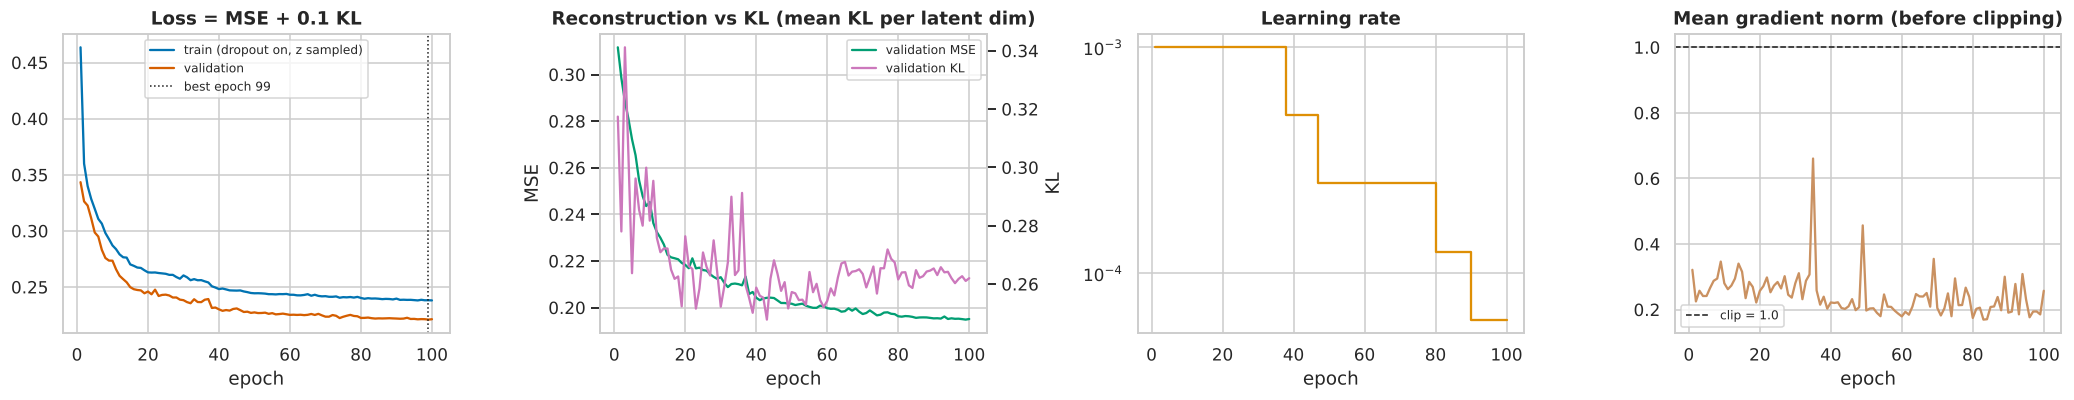

KL at the best epoch: 0.261 per latent dimension (bottleneck in use)


In [8]:
ep = np.arange(1, hist.epochs_run + 1)
fig, axes = plt.subplots(1, 4, figsize=(19, 3.8))
ax = axes[0]
ax.plot(ep, hist.train_loss, color=PAL[0], label="train (dropout on, z sampled)"); ax.plot(ep, hist.val_loss, color=PAL[3], label="validation")
ax.axvline(hist.best_epoch, color="k", ls=":", lw=1, label=f"best epoch {hist.best_epoch}")
ax.set_title("Loss = MSE + 0.1 KL"); ax.set_xlabel("epoch"); ax.legend(fontsize=8)
ax = axes[1]
ax.plot(ep, hist.val_mse, color=PAL[2], label="validation MSE"); ax.set_xlabel("epoch"); ax.set_ylabel("MSE")
ax2 = ax.twinx(); ax2.plot(ep, hist.val_kl, color=PAL[4], label="validation KL"); ax2.set_ylabel("KL"); ax2.grid(False)
ax.set_title("Reconstruction vs KL (mean KL per latent dim)")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax.legend(h1 + h2, l1 + l2, fontsize=8)
ax = axes[2]; ax.step(ep, hist.learning_rate, where="post", color=PAL[1]); ax.set_yscale("log"); ax.set_title("Learning rate"); ax.set_xlabel("epoch")
ax = axes[3]; ax.plot(ep, hist.gradient_norm, color=PAL[5]); ax.axhline(cfg.grad_clip_norm, color="k", ls="--", lw=1, label=f"clip = {cfg.grad_clip_norm}")
ax.set_title("Mean gradient norm (before clipping)"); ax.set_xlabel("epoch"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print(f"KL at the best epoch: {hist.val_kl[hist.best_epoch - 1]:.3f} per latent dimension "
      f"({'bottleneck in use' if hist.val_kl[hist.best_epoch - 1] > 0.05 else 'POSTERIOR COLLAPSE'})")

## 5. Threshold calibration

`AnomalyThresholdCalibrator` fits on the reconstruction errors of the **normal validation
windows**, computed exactly the way the detector scores (mean of 10 MC-Dropout passes - dropout
noise raises every error, so calibrating on a deterministic pass would make normal data look
abnormal): `threshold = mean + 3 * std`. It also keeps one threshold per feature, used to say
*which* features of a flagged window could not be reconstructed.

validation errors: mean 0.2101, std 0.0735 -> threshold 0.4327 (= mean + 3 std); calibrated on 1,690 windows
share of validation windows above the threshold (in-sample): 1.60%;  skewness of the errors: 4.5


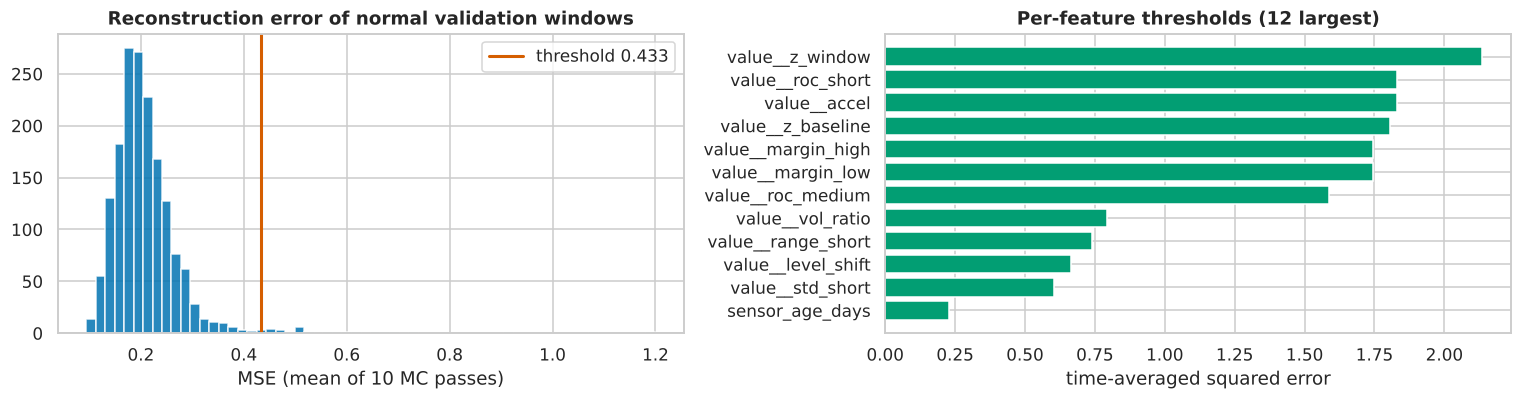

In [9]:
cal = detector.calibrator
val_err = reconstruction_errors(detector.model, val.x, mc_passes=detector.mc_passes).error
thr = cal.threshold
print(f"validation errors: mean {val_err.mean():.4f}, std {val_err.std(ddof=1):.4f} -> threshold {thr:.4f} "
      f"(= mean + {cal.sigma:g} std); calibrated on {cal.n_samples:,} windows")
print(f"share of validation windows above the threshold (in-sample): {np.mean(val_err > thr):.2%};  "
      f"skewness of the errors: {pd.Series(val_err).skew():.1f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
ax = axes[0]
ax.hist(val_err, bins=60, color=PAL[0], alpha=.85); ax.axvline(thr, color=PAL[3], lw=2, label=f"threshold {thr:.3f}")
ax.set_title("Reconstruction error of normal validation windows"); ax.set_xlabel("MSE (mean of 10 MC passes)"); ax.legend()
tp = pd.Series(cal.threshold_per_feature).sort_values(ascending=False)
ax = axes[1]; ax.barh(tp.index[:12][::-1], tp.values[:12][::-1], color=PAL[2])
ax.set_title("Per-feature thresholds (12 largest)"); ax.set_xlabel("time-averaged squared error")
plt.tight_layout(); plt.show()

## 6. Test-period evaluation

Windows are labelled by their **newest** row (the moment `detect()` is asked about). The detector is
built for collective anomalies, so point and contextual anomalies are reported as a reality check,
not as a target. `after` windows (an anomaly just left the newest row) are excluded from the
false-positive rate.

In [10]:
t0 = time.time()
res = detector.score_sequences(tst.x)
print(f"scored {len(tst):,} test windows x {detector.mc_passes} MC passes in {time.time()-t0:.0f}s")
tst_df = pd.DataFrame({"cls": cls, "error": res.error, "std": res.error_std, "score": res.score, "flag": res.is_anomaly,
                       "conf": res.confidence, "fraction": tst.anomaly_fraction})

order = ["normal", "point", "contextual", "collective", "after"]
rows = []
for c in order:
    s = tst_df[tst_df.cls == c]
    pos_vs_normal = tst_df[(tst_df.cls == "normal") | (tst_df.cls == c)]
    auc = roc_auc_score(pos_vs_normal.cls == c, pos_vs_normal.error) if c not in ("normal", "after") else np.nan
    ap = average_precision_score(pos_vs_normal.cls == c, pos_vs_normal.error) if c not in ("normal", "after") else np.nan
    rows.append(dict(window_class=c, n=len(s), flagged=int(s.flag.sum()), flag_rate=s.flag.mean(), median_error_over_threshold=s.error.median() / thr,
                     AUC_vs_normal=auc, AP_vs_normal=ap))
summary = pd.DataFrame(rows).set_index("window_class")
summary.round(3)

scored 17,208 test windows x 10 MC passes in 75s


,n,flagged,flag_rate,median_error_over_threshold,AUC_vs_normal,AP_vs_normal
window_class,,,,,,
normal,7303,72,0.010,0.465,NaN,NaN
point,308,258,0.838,1.561,0.991,0.858
contextual,706,244,0.346,0.774,0.857,0.573
collective,81,35,0.432,0.943,0.884,0.376
after,8810,5148,0.584,1.183,NaN,NaN


,n,detection_rate,median_error_over_threshold
episode share of window,,,
0-6 of 60 rows,14,0.143,0.557
6-12 of 60 rows,22,0.227,0.726
12-18 of 60 rows,21,0.619,1.167
18-30 of 60 rows,22,0.591,1.255


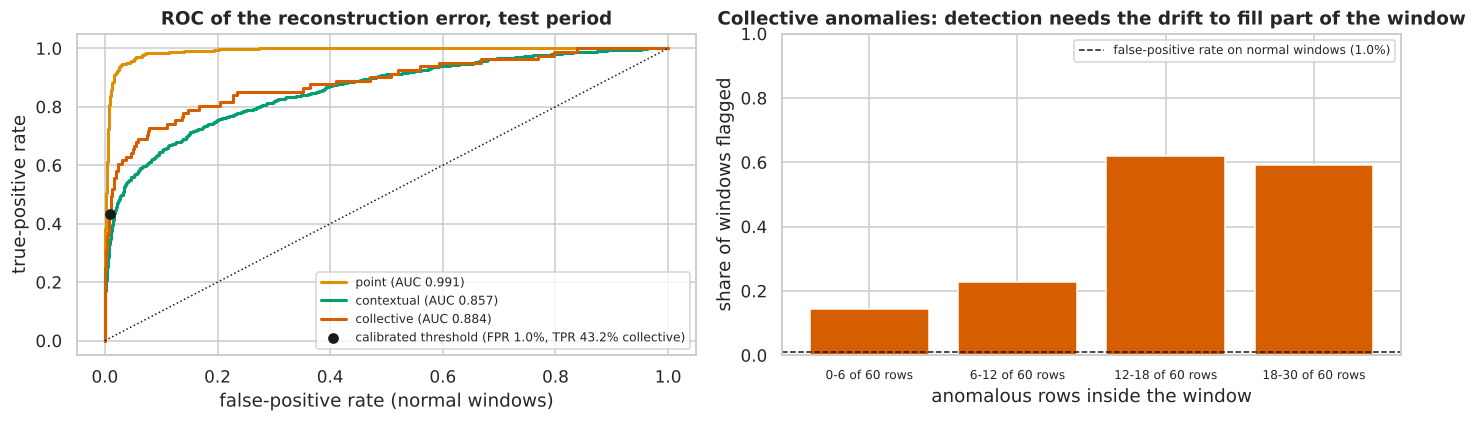

In [11]:
coll = tst_df[tst_df.cls == "collective"].copy()
edges = [0, 0.1, 0.2, 0.3, 0.5]
coll["episode share of window"] = pd.cut(coll.fraction, edges, labels=[f"{int(a*SEQ)}-{int(b*SEQ)} of {SEQ} rows" for a, b in zip(edges[:-1], edges[1:])])
by_frac = coll.groupby("episode share of window", observed=True).agg(n=("flag", "size"), detection_rate=("flag", "mean"), median_error_over_threshold=("error", lambda e: e.median() / thr))
display(by_frac.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ax = axes[0]
for c, col in zip(TYPES, (PAL[1], PAL[2], PAL[3])):
    m = tst_df[(tst_df.cls == "normal") | (tst_df.cls == c)]
    fpr, tpr, _ = roc_curve(m.cls == c, m.error)
    ax.plot(fpr, tpr, color=col, lw=2, label=f"{c} (AUC {roc_auc_score(m.cls == c, m.error):.3f})")
fl = tst_df[tst_df.cls == "normal"].flag.mean(); fr = tst_df[tst_df.cls == "collective"].flag.mean()
ax.scatter([fl], [fr], color="k", zorder=5, label=f"calibrated threshold (FPR {fl:.1%}, TPR {fr:.1%} collective)")
ax.plot([0, 1], [0, 1], "k:", lw=1); ax.set_xlabel("false-positive rate (normal windows)"); ax.set_ylabel("true-positive rate")
ax.set_title("ROC of the reconstruction error, test period"); ax.legend(fontsize=8, loc="lower right")
ax = axes[1]
ax.bar(by_frac.index.astype(str), by_frac.detection_rate, color=PAL[3]); ax.axhline(fl, color="k", ls="--", lw=1, label=f"false-positive rate on normal windows ({fl:.1%})")
ax.set_ylim(0, 1); ax.set_ylabel("share of windows flagged"); ax.set_xlabel("anomalous rows inside the window")
ax.set_title("Collective anomalies: detection needs the drift to fill part of the window"); ax.legend(fontsize=8)
plt.setp(ax.get_xticklabels(), fontsize=8); plt.tight_layout(); plt.show()

**A confound to check.** A window is labelled "collective" by its newest row, but nothing stops a *point*
anomaly from sitting earlier in the same window - and point anomalies are very easy for this model. Restricting to
collective windows whose anomalous rows are **all** collective separates the two:

In [12]:
def window_types(entity, end_ts):
    sel = (ds.entity_ids == entity) & (ds.timestamps > end_ts - SEQ) & (ds.timestamps <= end_ts)
    return set(ds.anomaly_type[sel][ds.y[sel]])

cidx = np.flatnonzero(cls == "collective")
pure = np.array([window_types(tst.entity_ids[i], tst.end_timestamps[i]) == {"collective"} for i in cidx])
pure_idx, mixed_idx = cidx[pure], cidx[~pure]
pure_mask = np.zeros(len(tst), bool); pure_mask[pure_idx] = True
norm_mask = cls == "normal"
sel = norm_mask | pure_mask
pure_auc = roc_auc_score(pure_mask[sel], res.error[sel]); pure_ap = average_precision_score(pure_mask[sel], res.error[sel])
pure_rate, mixed_rate = res.is_anomaly[pure_idx].mean(), res.is_anomaly[mixed_idx].mean() if len(mixed_idx) else np.nan
display(pd.DataFrame({"n": [len(pure_idx), len(mixed_idx)], "flagged": [int(res.is_anomaly[pure_idx].sum()), int(res.is_anomaly[mixed_idx].sum())],
                      "detection_rate": [pure_rate, mixed_rate]}, index=["only collective rows in window", "also other anomaly types in window"]).round(3))
print(f"pure collective vs normal windows: AUC {pure_auc:.3f}, AP {pure_ap:.3f}")

,n,flagged,detection_rate
only collective rows in window,43,8,0.186
also other anomaly types in window,38,27,0.711


pure collective vs normal windows: AUC 0.796, AP 0.062


## 7. Reconstruction-error distributions

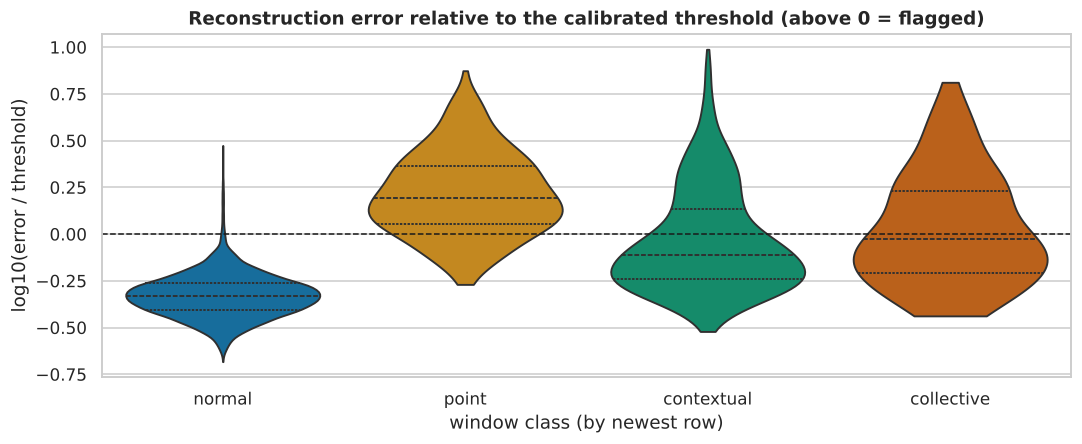

In [13]:
plot_df = tst_df[tst_df.cls != "after"].assign(log_ratio=lambda d: np.log10(d.error / thr))
fig, ax = plt.subplots(figsize=(10, 4.2))
sns.violinplot(data=plot_df, x="cls", y="log_ratio", order=["normal", "point", "contextual", "collective"], cut=0, inner="quartile",
               palette=[PAL[0], PAL[1], PAL[2], PAL[3]], ax=ax)
ax.axhline(0, color="k", ls="--", lw=1); ax.set_xlabel("window class (by newest row)"); ax.set_ylabel("log10(error / threshold)")
ax.set_title("Reconstruction error relative to the calibrated threshold (above 0 = flagged)")
plt.tight_layout(); plt.show()

## 8. Example sequences

A detected collective window, the *most informative miss* (a collective window the model did not
flag; the one with the largest share of anomalous rows) and a typical normal window, each with the
model's reconstruction. Only windows whose anomalous rows are all collective are used (section 6).
Features shown are the three the detected window reconstructs worst relative to their usual error.
Shaded steps are the simulator's ground truth.

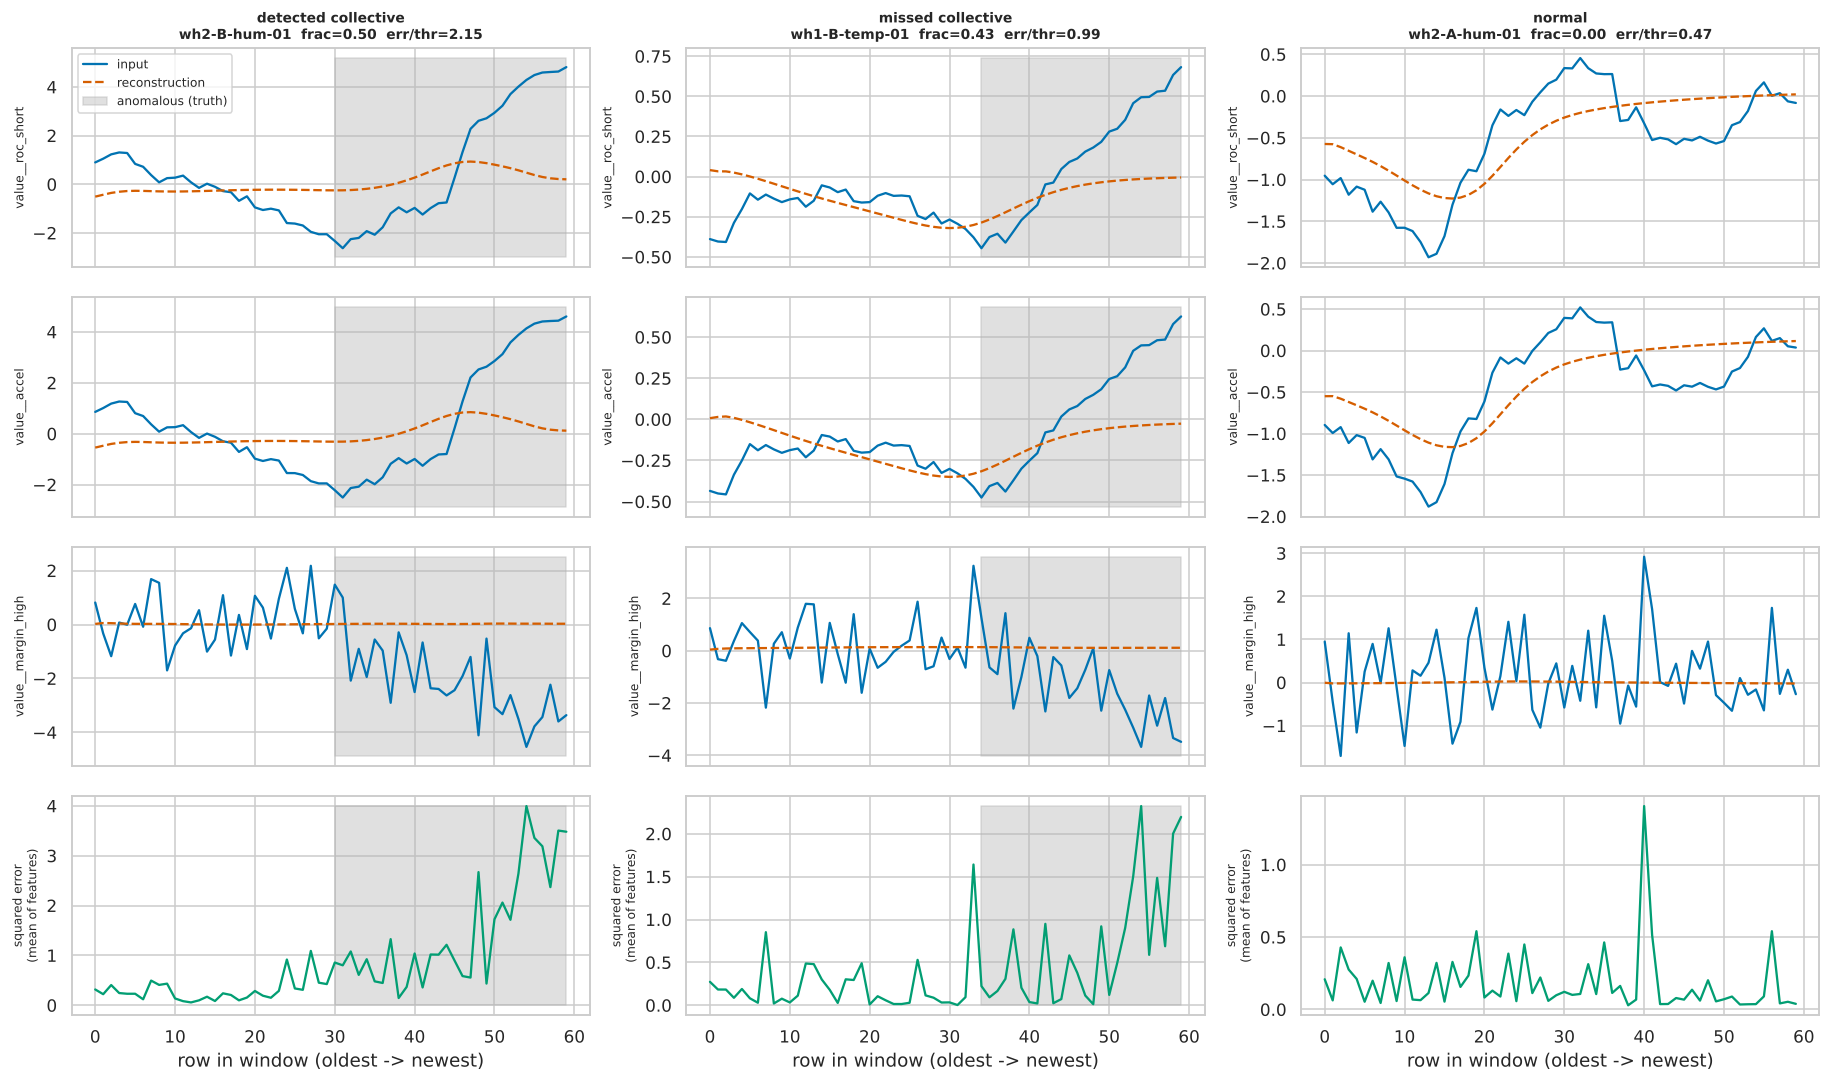

In [14]:
model = detector.model.eval()
def step_truth(entity, end_ts):
    sel = (ds.entity_ids == entity) & (ds.timestamps > end_ts - SEQ) & (ds.timestamps <= end_ts)
    y = ds.y[sel]
    assert len(y) == SEQ, len(y)
    return y

is_c = cls == "collective"
hit = np.flatnonzero(is_c & res.is_anomaly)
miss = np.flatnonzero(is_c & ~res.is_anomaly)
norm = np.flatnonzero(cls == "normal")
hit_pure = np.intersect1d(hit, pure_idx); miss_pure = np.intersect1d(miss, pure_idx)
hit = hit_pure if len(hit_pure) else hit; miss = miss_pure if len(miss_pure) else miss      # show windows with ONLY collective rows
picks = {"detected collective": hit[np.argmax(tst.anomaly_fraction[hit] * 10 + res.error[hit] / thr)] if len(hit) else None,
         "missed collective": miss[np.argmax(tst.anomaly_fraction[miss])] if len(miss) else None,
         "normal": norm[np.argsort(np.abs(res.error[norm] - np.median(res.error[norm])))[0]]}
picks = {k: v for k, v in picks.items() if v is not None}

ref = picks["detected collective"]
val_pf = reconstruction_errors(model, val.x).per_feature.mean(axis=0)       # typical per-feature error on normal data
show = np.argsort(-(res.per_feature[ref] - val_pf))[:3]                     # largest excess error in the detected window
with torch.no_grad():
    recon = {k: model(torch.as_tensor(tst.x[i:i + 1]))[0][0].numpy() for k, i in picks.items()}

fig, axes = plt.subplots(4, len(picks), figsize=(5.6 * len(picks), 10), sharex=True, squeeze=False)
for j, (title, i) in enumerate(picks.items()):
    truth = step_truth(tst.entity_ids[i], tst.end_timestamps[i])
    x, r = tst.x[i], recon[title]
    for row, f in enumerate(show):
        ax = axes[row, j]
        ax.plot(x[:, f], color=PAL[0], label="input"); ax.plot(r[:, f], color=PAL[3], ls="--", label="reconstruction")
        ax.fill_between(np.arange(SEQ), *ax.get_ylim(), where=truth, color="0.7", alpha=.4, step="mid", label="anomalous (truth)")
        ax.set_ylabel(names[f], fontsize=8)
        if row == 0:
            ax.set_title(f"{title}\n{tst.entity_ids[i]}  frac={tst.anomaly_fraction[i]:.2f}  err/thr={res.error[i] / thr:.2f}", fontsize=9)
    axes[3, j].plot(((x - r) ** 2).mean(axis=1), color=PAL[2]); axes[3, j].fill_between(np.arange(SEQ), 0, ((x - r) ** 2).mean(axis=1).max(), where=truth, color="0.7", alpha=.4, step="mid")
    axes[3, j].set_ylabel("squared error\n(mean of features)", fontsize=8); axes[3, j].set_xlabel("row in window (oldest -> newest)")
axes[0, 0].legend(fontsize=8, loc="best")
plt.tight_layout(); plt.show()

## 9. Localisation: which features does a flagged window blame?

`which_features_anomalous` lists the features whose time-averaged error exceeds their own
threshold. Share of flagged collective windows that blame each feature, against the share of
*normal* windows that do (the baseline of per-feature false alarms):

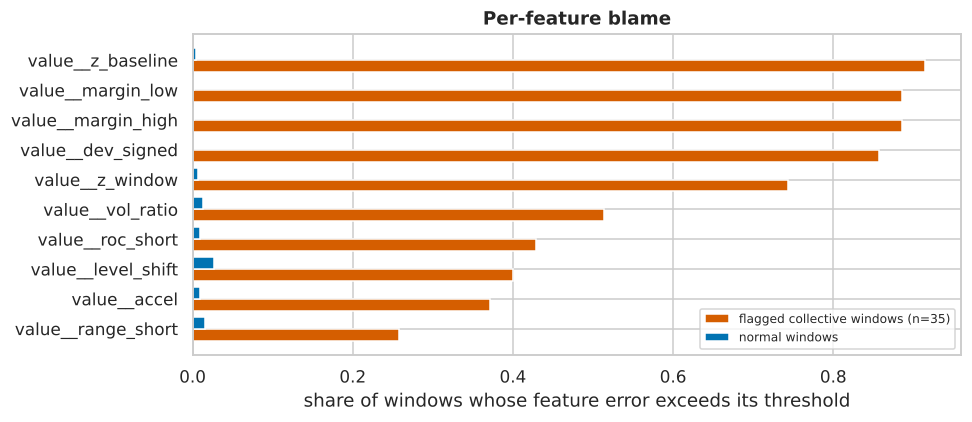

flagged collective windows name a median of 6 features (normal windows: 0)


In [15]:
flag_c = is_c & res.is_anomaly
rate_c = res.feature_exceeds[flag_c].mean(axis=0)
rate_n = res.feature_exceeds[cls == "normal"].mean(axis=0)
loc = pd.DataFrame({"flagged_collective": rate_c, "normal_windows": rate_n}, index=names)
loc["lift"] = loc.flagged_collective / loc.normal_windows.clip(lower=1e-3)
top = loc.sort_values("flagged_collective", ascending=False).head(10)
fig, ax = plt.subplots(figsize=(9, 4))
y = np.arange(len(top)); ax.barh(y + .2, top.flagged_collective, .4, color=PAL[3], label=f"flagged collective windows (n={int(flag_c.sum())})")
ax.barh(y - .2, top.normal_windows, .4, color=PAL[0], label="normal windows"); ax.set_yticks(y); ax.set_yticklabels(top.index); ax.invert_yaxis()
ax.set_xlabel("share of windows whose feature error exceeds its threshold"); ax.set_title("Per-feature blame"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
n_named = res.feature_exceeds[flag_c].sum(axis=1)
print(f"flagged collective windows name a median of {np.median(n_named):.0f} features (normal windows: {np.median(res.feature_exceeds[cls == 'normal'].sum(axis=1)):.0f})")

## 10. MC-Dropout uncertainty

Each window goes through 10 stochastic passes; `error_std` is their spread and
`confidence = erf(|error - threshold| / (sqrt(2) * error_std))` is the probability that the verdict
survives that noise. Is it informative? Decisions on `normal` and `collective` windows, grouped by
confidence (note the class imbalance: most decisions are easy normals, so overall accuracy flatters it):

,n,accuracy,flagged
confidence,,,
<0.5,17,0.471,0.529
0.5-0.9,27,0.630,0.333
0.9-0.99,27,0.630,0.370
>=0.99,7313,0.988,0.011


relative MC spread (std / error): median 1.3%, 95th percentile 4.3%


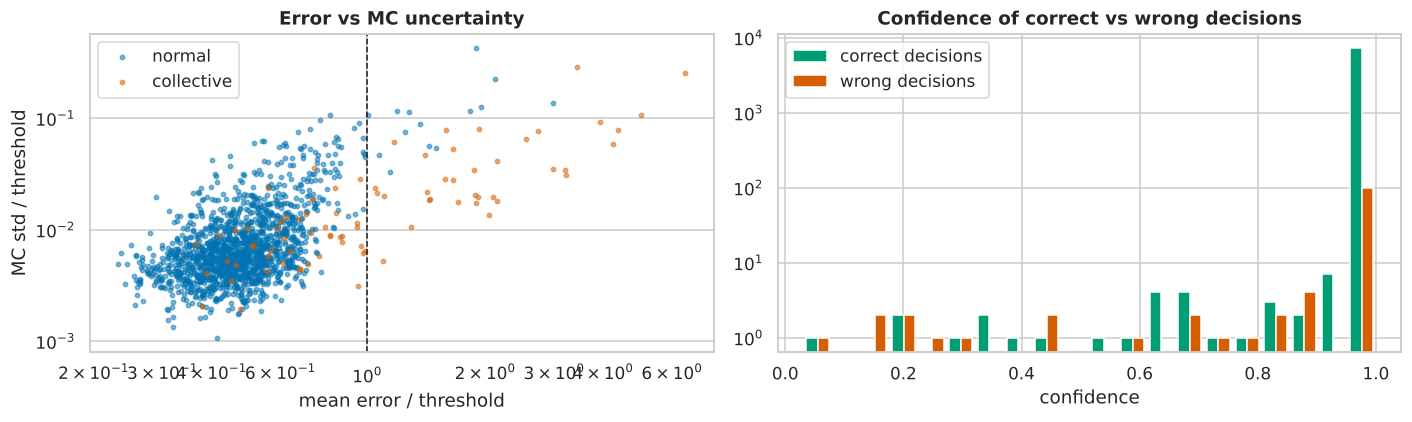

In [16]:
dec = tst_df[tst_df.cls.isin(["normal", "collective"])].assign(truth=lambda d: d.cls == "collective")
dec["correct"] = dec.flag == dec.truth
bins = [0, 0.5, 0.9, 0.99, 1.0001]
dec["confidence"] = pd.cut(dec.conf, bins, right=False, labels=["<0.5", "0.5-0.9", "0.9-0.99", ">=0.99"])
conf_tab = dec.groupby("confidence", observed=True).agg(n=("correct", "size"), accuracy=("correct", "mean"), flagged=("flag", "mean"))
display(conf_tab.round(3))
print(f"relative MC spread (std / error): median {np.median(res.error_std / res.error):.1%}, 95th percentile {np.percentile(res.error_std / res.error, 95):.1%}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ax = axes[0]
for c, col in zip(["normal", "collective"], (PAL[0], PAL[3])):
    s = tst_df[tst_df.cls == c].sample(min(1500, (tst_df.cls == c).sum()), random_state=0)
    ax.scatter(s.error / thr, s["std"] / thr, s=8, alpha=.5, color=col, label=c)
ax.axvline(1, color="k", ls="--", lw=1); ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("mean error / threshold"); ax.set_ylabel("MC std / threshold"); ax.set_title("Error vs MC uncertainty"); ax.legend()
ax = axes[1]
ax.hist([dec[dec.correct].conf, dec[~dec.correct].conf], bins=20, label=["correct decisions", "wrong decisions"], color=[PAL[2], PAL[3]], log=True)
ax.set_xlabel("confidence"); ax.set_title("Confidence of correct vs wrong decisions"); ax.legend()
plt.tight_layout(); plt.show()

## 11. Serving check: the detector on a live feature store

Everything above used offline windows. Here a *fresh* stream is replayed through the real Day 5/6
path - `WindowedAggregator` -> `FeatureCache` -> `FeaturePipeline.sequences` - with the training
scaler, and `detect_many` is asked about all sensors after 5 minutes (history still too short:
a warm-up result, not a guess on padded data) and after 20 minutes. The checkpoint round trip
(`to_checkpoint` / `from_checkpoint`) is exercised on the way.

In [17]:
from src.kafka.feature_cache import FeatureCache
from src.kafka.schemas import KafkaMessage
from src.kafka.stream_processor import WindowedAggregator
from src.data_simulation.orchestrator import SimulationOrchestrator
from src.models.feature_engineering import FeaturePipeline

cache = FeatureCache(); pipe = FeaturePipeline(cache); pipe.scalers["warehouse"] = scaler
live = LSTMAutoencoderDetector.from_checkpoint(detector.to_checkpoint(), sequences=pipe.sequences)
agg = WindowedAggregator()
sim = get_config().simulation.model_copy(update={"seed": 11})
start = T(21, 3, 0)
sensors = sorted(set(ds.entity_ids))
snap = {}
from collections import defaultdict, deque
recent = defaultdict(lambda: deque(maxlen=SEQ))          # ground truth of the last SEQ events per sensor
for ev in SimulationOrchestrator.from_config(sim, start_time=start, include_orders=False).stream(1200, throttle=False):
    if ev["source_type"] != "warehouse":
        continue
    msg = KafkaMessage.from_payload("warehouse", dict(ev["payload"]))
    for f in agg.process_message(msg).features:
        cache.store_features(msg.entity_id, f)
    recent[msg.entity_id].append(ev["payload"].get("anomaly_type"))
    elapsed = (datetime.fromisoformat(str(ev["payload"]["timestamp"]).replace("Z", "+00:00")) - start).total_seconds()
    if "5 min" not in snap and elapsed >= 300:
        snap["5 min"] = live.detect_many(sensors)
snap["20 min"] = live.detect_many(sensors)

def table(results):
    return pd.DataFrame([dict(sensor=r.entity_id, warming_up=r.details["warming_up"], real_steps=r.details["real_steps"],
                              truth_in_window=", ".join(sorted({t for t in recent[r.entity_id] if t})) or "none",
                              score=round(r.score, 3), flagged=r.is_anomaly, confidence=round(r.confidence, 3),
                              error_over_threshold=None if r.details["warming_up"] else round(r.details["reconstruction_error"] / r.details["threshold"], 2),
                              blamed=", ".join(r.details.get("which_features_anomalous", [])[:3])) for r in results]).set_index("sensor")
for k, r in snap.items():
    print(f"--- after {k} of stream: {sum(x.details['warming_up'] for x in r)} of {len(r)} sensors still warming up")
live_tab = table(snap["20 min"])
display(live_tab)
print(pd.crosstab(live_tab.truth_in_window != "none", live_tab.flagged, rownames=["anomaly in window (truth)"], colnames=["flagged"]).to_string())

t0 = time.perf_counter(); [live.detect_many(sensors) for _ in range(20)]; batch_ms = (time.perf_counter() - t0) / 20 * 1000
t0 = time.perf_counter(); [live.detect(sensors[0]) for _ in range(50)]; single_ms = (time.perf_counter() - t0) / 50 * 1000
print(f"detect(): {single_ms:.1f} ms per sensor;  detect_many({len(sensors)} sensors): {batch_ms:.1f} ms  (end-to-end budget: 500 ms)")

--- after 5 min of stream: 12 of 12 sensors still warming up
--- after 20 min of stream: 0 of 12 sensors still warming up


,warming_up,real_steps,truth_in_window,score,flagged,confidence,error_over_threshold,blamed
sensor,,,,,,,,
wh1-A-hum-01,False,60,contextual,0.408,False,1.0,0.69,sensor_age_days
wh1-A-temp-01,False,60,point,0.508,True,1.0,1.03,"value__dev_signed, sensor_age_days, value__z_w..."
wh1-B-hum-01,False,60,"collective, contextual",0.595,True,1.0,1.47,"sensor_age_days, value__margin_low, value__mar..."
wh1-B-temp-01,False,60,point,0.694,True,1.0,2.27,"value__dev_signed, sensor_age_days, value__mar..."
wh1-C-hum-01,False,60,"contextual, point",0.801,True,1.0,4.01,"value__dev_signed, sensor_age_days, value__std..."
wh1-C-temp-01,False,60,point,0.579,True,1.0,1.37,"value__dev_signed, value__margin_low, value__m..."
wh2-A-hum-01,False,60,point,0.595,True,1.0,1.47,"value__dev_signed, value__margin_low, value__m..."
wh2-A-temp-01,False,60,point,0.492,False,1.0,0.97,"value__dev_signed, value__margin_low, value__m..."
wh2-B-hum-01,False,60,point,0.753,True,1.0,3.05,"value__dev_signed, sensor_age_days, value__mar..."


flagged                    False  True 
anomaly in window (truth)              
False                          1      0
True                           3      8


detect(): 8.1 ms per sensor;  detect_many(12 sensors): 72.5 ms  (end-to-end budget: 500 ms)


## 12. Save to the model registry

In [18]:
flag_normal = float(tst_df[tst_df.cls == "normal"].flag.mean())
rec_coll = float(tst_df[tst_df.cls == "collective"].flag.mean())
metrics = {"test_false_positive_rate": flag_normal, "test_collective_detection_rate": rec_coll,
           "test_auc_collective": float(summary.loc["collective", "AUC_vs_normal"]), "test_ap_collective": float(summary.loc["collective", "AP_vs_normal"]),
           "val_best_loss": float(hist.best_val_loss), "threshold": float(thr)}
registry = ModelRegistry(ROOT / "model_registry")
version = detector.save(registry, metrics=metrics,
                        hyperparams={"epochs_run": hist.epochs_run, "best_epoch": hist.best_epoch, "seed": SEED, "stride": 10},
                        extra={"scaler": scaler.to_dict(), "columns": list(cols), "notebook": "notebooks/04_lstm_autoencoder_training.ipynb",
                               "protocol": "simulated warehouse, seed 7; train 22:00-00:30, validation 00:30-01:30, test 01:30-05:30 UTC"})
back = LSTMAutoencoderDetector.load(registry, version.version)
probe = tst.x[:64]
same = np.allclose(reconstruction_errors(back.model, probe).error, reconstruction_errors(detector.model, probe).error, rtol=1e-5)
print(f"saved lstm_autoencoder/{version.version}; reload reproduces the errors: {same}; threshold preserved: {back.calibrator.threshold == thr}")

saved lstm_autoencoder/20261123T010949901460Z; reload reproduces the errors: True; threshold preserved: True


## 13. Findings

In [19]:
nrm, col, pt, ctx, aft = (summary.loc[c] for c in ("normal", "collective", "point", "contextual", "after"))
top_blame = ", ".join(f"`{n}`" for n in loc.sort_values("flagged_collective", ascending=False).index[:3])
hi = by_frac.detection_rate.iloc[-1]; lo = by_frac.detection_rate.iloc[0]
lowconf = conf_tab.loc[conf_tab.index != ">=0.99"]; lowconf_acc = (lowconf.accuracy * lowconf.n).sum() / lowconf.n.sum()
cap_note = (f"Training stopped at the {cfg.max_epochs}-epoch cap, not by early stopping (best epoch {hist.best_epoch}), so more epochs might help - not tried. "
            if not hist.stopped_early else f"Training stopped early at epoch {hist.epochs_run} (best {hist.best_epoch}). ")
display(Markdown(f'''
**Results on the test period ({SEG["test"][0]:%H:%M} - {SEG["test"][1]:%H:%M} UTC, {len(tst):,} windows)**

| | value |
|---|---|
| threshold (mean + {cal.sigma:g} std of normal validation errors) | {thr:.4f} |
| false-positive rate on fully normal windows | {nrm.flag_rate:.2%} ({int(nrm.flagged)}/{int(nrm.n)}) |
| collective windows flagged | {col.flag_rate:.1%} ({int(col.flagged)}/{int(col.n)}), AUC {col.AUC_vs_normal:.3f}, AP {col.AP_vs_normal:.3f} |
| ... only windows with nothing but collective rows | {pure_rate:.1%} ({int(res.is_anomaly[pure_idx].sum())}/{len(pure_idx)}), AUC {pure_auc:.3f}, AP {pure_ap:.3f} |
| point windows flagged | {pt.flag_rate:.1%} ({int(pt.flagged)}/{int(pt.n)}), AUC {pt.AUC_vs_normal:.3f} |
| contextual windows flagged | {ctx.flag_rate:.1%} ({int(ctx.flagged)}/{int(ctx.n)}), AUC {ctx.AUC_vs_normal:.3f} |
| collective detection when the drift fills the smallest / largest share of the window | {lo:.1%} / {hi:.1%} |
| windows whose anomaly just left the newest row (`after`) still flagged | {aft.flag_rate:.1%} ({int(aft.flagged)}/{int(aft.n)}) |
| flagged collective windows blame most often | {top_blame} |
| inference | {single_ms:.1f} ms per sensor, {batch_ms:.1f} ms for {len(sensors)} sensors |
| training | {hist.epochs_run} epochs, {train_s:.0f}s on {torch.get_num_threads()} CPU threads |

**What this says**

* **Collective detection is weak: moderate on mixed windows, poor on isolated drifts.** At a ~{nrm.flag_rate:.0%} false-positive rate the model flags {col.flag_rate:.0%} of collective windows
  ({pure_rate:.0%} when only collective rows are present); the error ranks them well above normal data (AUC {col.AUC_vs_normal:.2f}) but precision at the
  threshold is limited (AP {col.AP_vs_normal:.2f}, with collective windows only {col.n / (nrm.n + col.n):.1%} of the evaluated set).
  It is a window-level model: a drift that has just started is nearly invisible ({lo:.0%} when it occupies the fewest rows, {hi:.0%} at most), so *time to detect* per
  episode is what the Day 13 evaluator must measure.
* **It is not a collective-only detector.** Large spikes dominate a reconstruction error, so point windows are flagged most reliably
  ({pt.flag_rate:.0%}, AUC {pt.AUC_vs_normal:.2f}) and contextual windows partly ({ctx.flag_rate:.0%}). That overlap is useful for the ensemble, but it means the
  "collective" label of this score must not be taken at face value - hence the purity check in section 6.
* **Alerts outlive the anomaly.** A window keeps an anomalous row for up to {SEQ} further rows, and {aft.flag_rate:.0%} of such windows are still flagged:
  expect alerts to persist up to a window length after the event. The Day 12 deduplicator / severity logic has to account for this.
* **Localisation is interpretable but coarse.** Flagged collective windows blame mostly the deviation-from-baseline features ({top_blame}), which is the right physical story for a drift.
* **MC-Dropout confidence is a borderline indicator, not a calibrated probability.** The spread is small (median {np.median(res.error_std / res.error):.1%} of the error); decisions with confidence
  below 0.99 are right {lowconf_acc:.0%} of the time (n={int(lowconf.n.sum())}) against {conf_tab.loc[">=0.99", "accuracy"]:.1%} above it, but the latter is dominated by easy normal windows.
* {cap_note}The clock-encoding exclusion (section 2) was motivated by the diagnostic but its effect on the final metrics was not measured.
* `detect()` is safe on a cold feature store: it returns a warm-up result until the entity has enough warm history (section 11). The scaler used for training must be deployed with the
  model; it is stored in the registry entry.

**Hand-off to Day 12 (ensemble):** use `details["reconstruction_error"]` and `score` (0.5 at the threshold) as ensemble inputs, `confidence` as a second feature, and
`which_features_anomalous` for the alert explanation.
'''))


**Results on the test period (01:30 - 05:30 UTC, 17,208 windows)**

| | value |
|---|---|
| threshold (mean + 3 std of normal validation errors) | 0.4327 |
| false-positive rate on fully normal windows | 0.99% (72/7303) |
| collective windows flagged | 43.2% (35/81), AUC 0.884, AP 0.376 |
| ... only windows with nothing but collective rows | 18.6% (8/43), AUC 0.796, AP 0.062 |
| point windows flagged | 83.8% (258/308), AUC 0.991 |
| contextual windows flagged | 34.6% (244/706), AUC 0.857 |
| collective detection when the drift fills the smallest / largest share of the window | 14.3% / 59.1% |
| windows whose anomaly just left the newest row (`after`) still flagged | 58.4% (5148/8810) |
| flagged collective windows blame most often | `value__z_baseline`, `value__margin_low`, `value__margin_high` |
| inference | 8.1 ms per sensor, 72.5 ms for 12 sensors |
| training | 100 epochs, 597s on 2 CPU threads |

**What this says**

* **Collective detection is weak: moderate on mixed windows, poor on isolated drifts.** At a ~1% false-positive rate the model flags 43% of collective windows
  (19% when only collective rows are present); the error ranks them well above normal data (AUC 0.88) but precision at the
  threshold is limited (AP 0.38, with collective windows only 1.1% of the evaluated set).
  It is a window-level model: a drift that has just started is nearly invisible (14% when it occupies the fewest rows, 59% at most), so *time to detect* per
  episode is what the Day 13 evaluator must measure.
* **It is not a collective-only detector.** Large spikes dominate a reconstruction error, so point windows are flagged most reliably
  (84%, AUC 0.99) and contextual windows partly (35%). That overlap is useful for the ensemble, but it means the
  "collective" label of this score must not be taken at face value - hence the purity check in section 6.
* **Alerts outlive the anomaly.** A window keeps an anomalous row for up to 60 further rows, and 58% of such windows are still flagged:
  expect alerts to persist up to a window length after the event. The Day 12 deduplicator / severity logic has to account for this.
* **Localisation is interpretable but coarse.** Flagged collective windows blame mostly the deviation-from-baseline features (`value__z_baseline`, `value__margin_low`, `value__margin_high`), which is the right physical story for a drift.
* **MC-Dropout confidence is a borderline indicator, not a calibrated probability.** The spread is small (median 1.3% of the error); decisions with confidence
  below 0.99 are right 59% of the time (n=71) against 98.8% above it, but the latter is dominated by easy normal windows.
* Training stopped at the 100-epoch cap, not by early stopping (best epoch 99), so more epochs might help - not tried. The clock-encoding exclusion (section 2) was motivated by the diagnostic but its effect on the final metrics was not measured.
* `detect()` is safe on a cold feature store: it returns a warm-up result until the entity has enough warm history (section 11). The scaler used for training must be deployed with the
  model; it is stored in the registry entry.

**Hand-off to Day 12 (ensemble):** use `details["reconstruction_error"]` and `score` (0.5 at the threshold) as ensemble inputs, `confidence` as a second feature, and
`which_features_anomalous` for the alert explanation.
